# Spatial GRN Integration of the Dentate Gyrus

## Tutorial 3: Impute spatial RAS(regulon activate score)

**Author:** Xuan Cao  
**Affiliation:** Icahn School of Medicine at Mount Sinai  
**Email:** xuan.cao@mssm.edu  

**Contributors:** Donghoon Lee, Panos Roussos  

**Date:** Sep 6, 2026  

---

### Overview
This notebook demonstrates a pipeline for spatial imputation and integration of gene regulatory networks (GRNs) in the dentate gyrus. We between single-cell multiome profiles and spatial transcriptomics data to enable downstream GRN inference in a spatially resolved context.

### Contents
1. Data loading  
2. Impute spatial RAS  
3. Visualize regulon

# Imports

In [3]:
import scanpy as sc
import os
from pathlib import Path
import glob
import pandas as pd
import time
import numpy as np
import sys
import pickle

# Inital setting for plot size
sc.set_figure_params(scanpy=True, dpi=100, dpi_save=150, fontsize=12)
sc.set_figure_params(dpi=100, color_map = 'viridis_r')
sc.settings.verbosity = 1
sc.logging.print_header()
from matplotlib import rcParams,rc_context
import matplotlib.pyplot as plt
import seaborn as sns

import tangram as tg

import warnings
warnings.filterwarnings('ignore')

# Set dirs

In [9]:
master_dir = 'SpatialGRN/Output'
tangram_dir = f'{master_dir}/01.tangram_align'
cistopic_dir = f'{master_dir}/02a.pycisTopic'
cistarget_dir = f'{master_dir}/02b.pycisTarget'
scplus_dir = f'{master_dir}/02c.scenic+'
spras_dir = f'{master_dir}/03.spatial_RAS'

if not os.path.exists(spras_dir):os.makedirs(spras_dir)


# 1. Data loading

## 1.1 Load RAS from snMultiome

In [50]:
auc_sn = sc.read_h5ad(f'{scplus_dir}/08.eRegulon_AUC_Gene.h5ad') 
auc_sn

AnnData object with n_obs × n_vars = 9856 × 1851
    obs: 'class', 'subclass', 'subtype'

## 1.2 Load map matrix

In [51]:
ad_map = sc.read_h5ad(f'{tangram_dir}/ad_map.h5ad')
ad_map

AnnData object with n_obs × n_vars = 9856 × 44997
    obs: 'class', 'subclass', 'subtype'
    var: 'class', 'subclass', 'subtype', 'uniform_density', 'rna_count_based_density'
    uns: 'train_genes_df', 'training_history'

## 1.3 Load Xenium data

In [52]:
ad_sp = sc.read_h5ad('data/human_DG_xenium.h5ad')
ad_sp

AnnData object with n_obs × n_vars = 44997 × 366
    obs: 'class', 'subclass', 'subtype'
    uns: 'subclass_colors'
    obsm: 'spatial'
    layers: 'counts', 'logCPM'

# 2. Impute spatial RAS

In [33]:
import time

def impute_sp(
    ad_sc,
    ad_map,
    ad_sp

):
    ad_sc_new = ad_sc.copy() 
    ad_map = ad_map[ad_sc.obs_names]
    
    ### New spatial data via aligned single cells
    print(time.strftime("%Y-%m-%d %H:%M:%S", time.localtime()), ': Start impute for spatial!',sep="")
    ad_ge_sp = tg.project_genes(adata_map=ad_map, adata_sc=ad_sc)
    print('ad_ge_sp')
    print(ad_ge_sp)
    print(time.strftime("%Y-%m-%d %H:%M:%S", time.localtime()), ': Done impute for spatial!',sep="")
     
    # add spatial information
    ad_ge_sp.obsm['spatial']= ad_sp[ad_ge_sp.obs_names].obsm['spatial']
    
    ### correct the gene names from lower case to upper case
    ## align the gene names
    genes_imputed = ad_ge_sp.var_names.to_list()
    genes_measured = ad_sc_new.var_names.to_list()
    aligned = [(a, b) for a in genes_imputed for b in genes_measured if a.lower() == b.lower()]
    aligned = pd.DataFrame(aligned,columns=['imputed','measured'])
    aligned[aligned['imputed'] != aligned['measured']]
    ad_ge_sp.var_names = aligned['measured'].to_list()
    
    return(ad_ge_sp)

In [53]:
## check barcode
ad_map.obs_names = ad_map.obs_names + "___human_DG"
barcodes_common = list(set(ad_map.obs_names) & set(auc_sn.obs_names))
print(len(barcodes_common))
ad_map = ad_map[barcodes_common]
auc_sn = auc_sn[barcodes_common]
    


9856


In [54]:
#impute
auc_sp = impute_sp(ad_sc=auc_sn,ad_map=ad_map, ad_sp=ad_sp)

2026-09-09 07:48:13: Start impute for spatial!
ad_ge_sp
AnnData object with n_obs × n_vars = 44997 × 1851
    obs: 'class', 'subclass', 'subtype', 'uniform_density', 'rna_count_based_density'
    var: 'n_cells', 'is_training'
2026-09-09 07:48:22: Done impute for spatial!


In [55]:
## save auc_sp
auc_sp.write_h5ad(f'{spras_dir}/auc_sp.h5ad')

# 3. Visualization

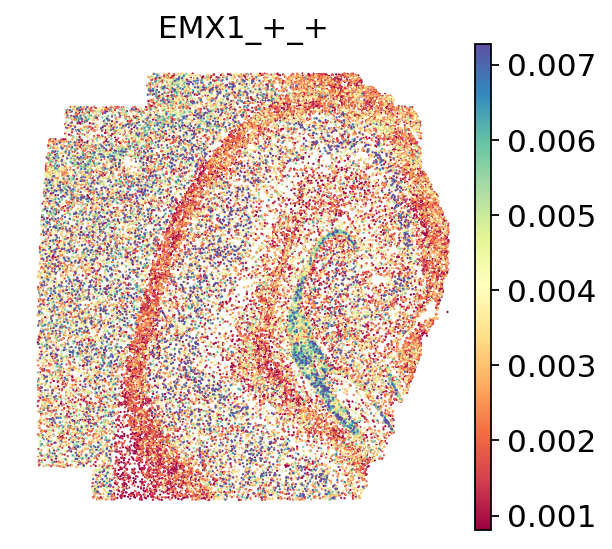

In [81]:
regulons = ['EMX1_+_+']
sc.set_figure_params(scanpy=True, fontsize=14, figsize=(4,4))
sc.pl.spatial(auc_sp,color=regulons,size=10,spot_size=5,frameon=False,cmap='Spectral',ncols=4,
              wspace=0.2,vmax='p95',vmin='p10')


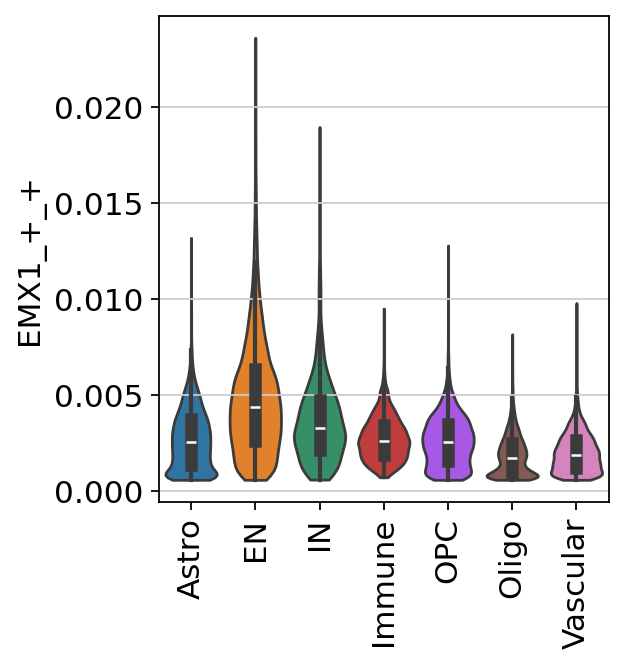

In [82]:
regulons = ['EMX1_+_+']

sc.pl.violin(
    auc_sp,
    keys=regulons,
    groupby="class",
    stripplot=False, 
    inner="box",
    rotation = 90
)